# 03 — Validation

Cœur du projet. Cas limites, benchmark arbre, monotonies, convergence, duality gap.

Chaque graphique produit ici alimente une section de `docs/model_validation_note.md`.

# Introduction

This notebook establishes two things.

**1. Correctness of the pricer.** A swing option has no closed-form value —
that is the reason for the Monte Carlo in the first place. Validation
therefore proceeds by degenerating the contract into objects whose price
*is* known analytically (forced exercise, decoupled dates, single date) and
checking that the engine recovers them. Every discrepancy is reported in
standard errors rather than percentages: it is the only scale that tells
whether a difference is significant.

Assumed limitation: these cases do not cover the regime of interest, where
the global volume cap binds without forcing every decision. No analytical
reference exists there; the trinomial tree of milestone 2 will provide one.

**2. Justification of the numerical choices.** Degree of the regression
basis, number of volume grid nodes, and number of Monte Carlo paths — both
for fitting the policy and for evaluating it. Each is set by a measurement
reproduced in this notebook, not carried over from the literature.

The underlying model is a GBM. This is *not* a realistic model for energy
prices: it is used here solely because it gives access to closed-form
references. Mean-reverting models are the subject of milestone 4.

## Assumption not enforced by the code

The engine assumes the model is specified under the **risk-neutral measure**:
its drift must equal the contract rate. Nothing checks this at runtime.
Simulating under the physical measure while discounting at the risk-free rate
would produce a wrong price that no structural test would catch.

## The contract and its degenerate cases

### General formulation

At each exercise date $t_1 < \dots < t_N$ the holder withdraws a volume
$q_i$, paying $K$ per unit. Writing $Q_i = \sum_{k<i} q_k$ for the volume
already taken, the admissible set is

$$q_i \in \mathcal{A}_i(Q_i) = \big[q^-(i, Q_i),\; q^+(i, Q_i)\big]$$

$$q^+ = \min\big(q_{\max},\; Q_{\max} - Q_i\big), \qquad
q^- = \max\big(q_{\min},\; Q_{\min} - Q_i - (N - i - 1)\,q_{\max}\big)$$

The lower bound carries the catch-up term: it forces withdrawal once
$Q_{\min}$ can no longer be reached within the remaining dates.

The value function solves the Bellman recursion

$$V_i(S, Q) = \max_{q \in \mathcal{A}_i(Q)}
\Big\{ q\,(S - K) + \mathbb{E}^{\mathbb{Q}}\big[e^{-r\Delta_i} V_{i+1}(S_{i+1}, Q + q) \mid S_i = S\big] \Big\}$$

with terminal condition $V_{N+1}(S, Q) = -\alpha\,(Q_{\min} - Q)^+$.
The price is $V_1(S_0, 0)$. No closed form exists in general.

---

### Case 1 — Forced exercise (`FORCED`)

$$Q_{\min} = Q_{\max} = N q_{\max}, \qquad \alpha = 0$$

Then $q^+ = q^- = q_{\max}$ at every date: the admissible set is a
singleton and no decision is taken. The optionality vanishes and the
contract reduces to a strip of forwards.

$$V = \sum_{i=1}^{N} e^{-rt_i}\, q_{\max}\,\big(F(0, t_i) - K\big)$$

No $(\cdot)^+$: the holder withdraws even when $S < K$, so individual
cash flows may be negative, and so may the contract value.

**Tests:** `admissible_volume` in the fully constrained regime, and
discounting across several dates. The decisions are deterministic; the
payoffs are not, so the comparison is made within three standard errors.

---

### Case 2 — Decoupled dates (`FREE`)

$$q_{\min} = 0, \qquad Q_{\min} = 0, \qquad Q_{\max} = N q_{\max}$$

The global cap equals the sum of the local caps, so it can never bind:
$q^- = 0$ and $q^+ = q_{\max}$ regardless of $Q_i$. Taking volume today
costs nothing tomorrow, and the control problem separates:

$$\max_{q_1,\dots,q_N} \sum_i e^{-rt_i}\,\mathbb{E}^{\mathbb{Q}}\big[q_i(S_{t_i} - K)\big]
= \sum_i \max_{q_i \in [0, q_{\max}]} e^{-rt_i}\,\mathbb{E}^{\mathbb{Q}}\big[q_i(S_{t_i} - K)\big]$$

Each term is maximised at $q_i = q_{\max}\,\mathbf{1}_{\{S_{t_i} > K\}}$,
giving a strip of European calls:

$$V = \sum_{i=1}^{N} q_{\max}\cdot \mathrm{Black76}\big(F(0, t_i),\, K,\, \sigma,\, t_i,\, e^{-rt_i}\big)$$

**Tests:** the full backward recursion, the regression and the volume
interpolation. This is the most demanding of the analytical cases.

Note that the regression runs but does not influence any decision here:
with decoupled dates, the continuation value plays no role. This is why
Case 4 below is needed.

---

### Case 3 — Single date (`contrat_a(0)`)

$$N = 1, \qquad Q_{\max} = q_{\max}$$

No recursion at all. A European call.

$$V = q_{\max}\cdot \mathrm{Black76}\big(F(0, t_1),\, K,\, \sigma,\, t_1,\, e^{-rt_1}\big)$$

**Tests:** payoff and discounting in isolation. Diagnostic value rather
than coverage: it exercises no code path that Case 2 does not already
cover, but it localises a failure if Case 2 breaks.

---

### Case 4 — Bermudan (`BERM`)

$$Q_{\max} = q_{\max}, \qquad q_{\min} = 0, \qquad Q_{\min} = 0, \qquad N > 1$$

Once a full withdrawal occurs, $Q_{\max} - Q = 0$ and every later date has
$q^+ = 0$. A single exercise right remains, to be placed among $N$ dates:

$$V = q_{\max}\cdot \sup_{\tau \in \mathcal{T}}
\mathbb{E}^{\mathbb{Q}}\big[e^{-r\tau}(S_\tau - K)^+\big],
\qquad \mathcal{T} = \{\text{stopping times valued in } \{t_1,\dots,t_N\}\}$$

$\tau$ is a **stopping time**, not a date: the decision may depend on the
observed path. Since deterministic dates are themselves stopping times,

$$\max_i\, q_{\max} \mathrm{Black76}(t_i) \;\le\; V \;\le\;
\sum_i q_{\max} \mathrm{Black76}(t_i)$$

The lower bound is any fixed-date strategy; the upper bound is the strip,
which grants $N$ rights instead of one. The gap between $V$ and the lower
bound is the value of adapting the decision to information — and the first
quantity in this project that depends on the quality of the regression.

**Two regimes.**

Under $\mu = r$ (no convenience yield), early exercise is never optimal:
the classical result for a call on a non-dividend-paying asset. The
contract degenerates to the European call of maturity $t_N$, and the
bound above is attained. Useful as a fifth analytical case, but it tests
nothing about the exercise decision.

Under $\mu = r - \delta$ with $\delta > 0$ (convenience yield), early
exercise becomes optimal on part of the paths. The lower bound must then
be beaten strictly, and this is what the test asserts.

## Results

### Limit cases

All reported within three standard errors of the analytical reference.
Discrepancies are given in standard errors, not percentages.

| Case | Reference | LSMC | Std. error | Gap |
|---|---|---|---|---|
| Strip of calls | 10.4230 | 10.3953 | 0.0771 | −0.36 σ |
| Bermudan, no convenience yield | 3.4277 | 3.3917 | 0.0281 | −1.28 σ |

The remaining cases (forced strip, single-date European) pass within the
same tolerance.

### Bermudan: two regimes

Under $\mu = r$, no path exercises before $t_N$: 0.0 % at $t_0$ and $t_1$.
This is the classical result for a call on a non-dividend-paying asset.
The contract degenerates to the European call of maturity $t_N$, and the
test asserts nothing about the exercise decision.

Under $\mu = r - 0.08$ (convenience yield), early exercise becomes optimal
and the continuation value decreases with the date, as the set of
remaining exercise dates shrinks:

| Date | Continuation (not yet exercised) | Already exercised |
|---|---|---|
| $t_0$ | 2.6858 | — |
| $t_1$ | 2.6726 | 0.0 % of paths |
| $t_2$ | 1.8429 | 10.5 % |
| $t_3$ | 0.0000 | 21.1 % |

Price: 2.6232 ± 0.0217, against a best fixed-date strategy at 2.5515 —
**+3.3 σ**. This gap is the value of adapting the decision to observed
information, and it is the first quantity in the project whose magnitude
depends on the quality of the regression.

Continuation is zero at $t_3$ for both populations, confirming the
terminal condition and the exhaustion of the exercise right.

### Degree of the regression basis

Two regimes, depending on the size of the **fitting** sample.

With 1 000 fitting paths (100 000 for evaluation), the optimistic bias of
an in-sample valuation is measurable and widens with the degree:

| Degree | In-sample | Out-of-sample | Gap |
|---|---|---|---|
| 2 | 7.6239 | 7.5106 | +1.51 % |
| 3 | 7.6166 | 7.5380 | +1.04 % |
| 5 | 7.6014 | 7.5357 | +0.87 % |
| 8 | 7.6614 | 7.5342 | +1.69 % |
| 12 | 7.7088 | 7.5153 | +2.57 % |

With 100 000 fitting paths the effect disappears entirely: the gap stays
below 0.12 % in absolute value and shows no trend, even at degree 12. The
observations-to-parameters ratio is too favourable for the noise to be
exploitable.

**Conclusions.** Degrees 3 to 8 are indistinguishable: the out-of-sample
prices differ by less than 0.1 σ. Degree 2 underfits (−1 σ) and degree 12
overfits. Within the plateau, degree 3 is retained for cost (regression
cost grows as O(d²), over N × M regressions) and for robustness at
smaller fitting samples.

**Why maximising the price is a legitimate criterion.** The out-of-sample
price is a *lower bound*: any suboptimal policy yields less than the
optimum, so the gap $V^\star - \widehat V_{\text{out}}$ is exactly the
loss caused by an imperfect regression. Maximising $\widehat V_{\text{out}}$
therefore minimises that loss. **The criterion is legitimate only because
the evaluation sample is independent of the fitting sample: a degree that
inflated the price by exploiting fitting noise would gain nothing out of
sample.** Degree 12 illustrates this directly, with an in-sample price of
7.7088 against 7.5153 out of sample.

**Limitation.** Only one side of the bracket is being optimised here. The
trinomial tree (milestone 2) and the dual upper bound (milestone 3) will
supply the other: the upper bound is to be *minimised*, and the eventual
criterion is the width of the primal-dual gap, which measures the quality
of the numerical scheme without reference to any external benchmark.

**Assumption carried forward.** The 1.5 % to 2.6 % figures measure the
error incurred by the original Boogert–de Jong formulation, which
evaluates on the fitting sample. That error is negligible at the sample
size used throughout this project, which justifies the fit/evaluate split
rather than merely asserting it.

In [16]:
import numpy as np
import pandas as pd
import pytest
import matplotlib.pyplot as plt
from swingpricer.contracts.swing import SwingContract
from swingpricer.engines.analytic import forced_strip, strip_of_calls
from swingpricer.engines.lsmc import LSMCSwingEngine
from swingpricer.models.gbm import GBM


N_DATES = 4
Q_MAX = 1.0
S0 = 20.0
K = 20.0
VOL = 0.40
RATE = 0.03
DATES = np.arange(1, N_DATES +1)/N_DATES
MODEL = GBM(s0 = S0, vol = VOL, drift = RATE)

def contract(Qmin, Qmax):
    return SwingContract(DATES, K, 0.0, Q_MAX, Qmin, Qmax, 0.0, RATE)
#différents types de contrat
FORCED = contract(N_DATES * Q_MAX, N_DATES * Q_MAX)


### Monte Carlo error

The price is the empirical mean of $M$ i.i.d. discounted cash flows, one
per path, so its standard error is $\sigma/\sqrt{M}$ and

$$\log(\mathrm{se}) = \log \sigma - \tfrac{1}{2}\log M$$

A log-log plot of the standard error against the number of paths should
therefore have slope $-1/2$. The limit cases check that the estimator
converges to the right value; this checks that it converges at the right
*rate*, which no value-based test would catch: a slope away from $-1/2$
would signal that the paths are not independent.

Measured at fixed policy, so that only the evaluation sample varies.

In [7]:
paths_size = [2_500, 5_000, 10_000, 20_000, 40_000, 80_000]
stderrs = [LSMCSwingEngine(FORCED).price(MODEL, n, n, seed=7).stderr for n in paths_size]
slope = np.polyfit(np.log(paths_size), np.log(stderrs), 1)[0]
print(f"Empirical slop : {round(slope,3)} (theoritical : -0.5)")

Empirical slop : -0.5 (theoritical : -0.5)


### Exercise policy  

Aggregate prices say whether the engine is right; the policy says whether it is right for the right reason. A sound stopping rule has a decreasing exercise boundary that meets the strike at maturity.

In [17]:
BERM = contract(0.0, Q_MAX)
MODEL_CY = GBM(s0=S0, vol=VOL, drift=RATE - 0.08)

engine = LSMCSwingEngine(BERM)
paths_fit = MODEL_CY.simulate(DATES, 40_000, seed=7)
paths_eval = MODEL_CY.simulate(DATES, 40_000, seed=10007)

policy = engine.fit_policy(paths_fit)
prix, se, decisions = engine.evaluate_policy(policy, paths_eval, return_decisions=True)

# volume cumulated BEFORE each date: a path that has exercised is out
Q_avant = np.vstack([np.zeros(paths_eval.shape[0]), np.cumsum(decisions, axis=0)[:-1]])
encore_actif = Q_avant < 0.5
exerce = decisions > 0.5

frontiere, part = [], []
for i in range(N_DATES):
    actifs = encore_actif[i]
    exercants = exerce[i] & actifs
    part.append(exercants.sum() / actifs.sum() if actifs.any() else np.nan)
    frontiere.append(paths_eval[exercants, i].min() if exercants.any() else np.nan)

pd.DataFrame({
    "Date": DATES,
    "Still alive": encore_actif.sum(axis=1),
    "Exercise rate": part,
    "Boundary (min S exercised)": frontiere,
}).round(4)

,Date,Still alive,Exercise rate,Boundary (min S exercised)
0,0.25,40000,0.0269,28.3446
1,0.50,38923,0.0905,26.6994
2,0.75,35401,0.1142,24.6183
3,1.00,31359,0.2293,20.0016


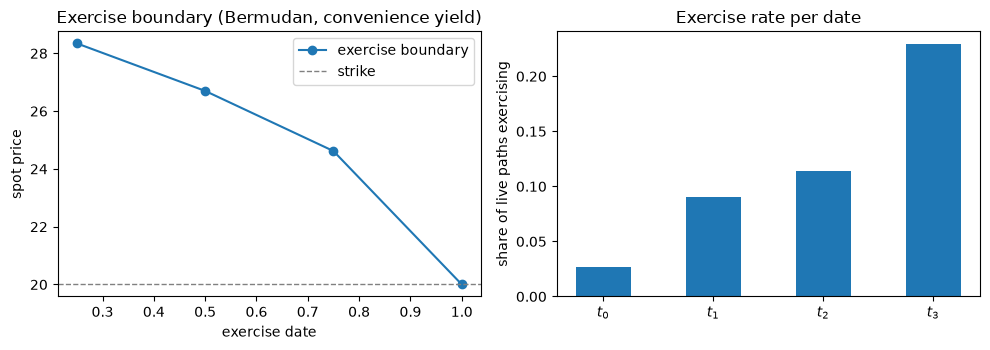

: 

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))

ax1.plot(DATES, frontiere, "o-", label="exercise boundary")
ax1.axhline(K, ls="--", c="grey", lw=1, label="strike")
ax1.set_xlabel("exercise date")
ax1.set_ylabel("spot price")
ax1.set_title("Exercise boundary (Bermudan, convenience yield)")
ax1.legend()

ax2.bar(range(N_DATES), part, width=0.5)
ax2.set_xticks(range(N_DATES), [f"$t_{i}$" for i in range(N_DATES)])
ax2.set_ylabel("share of live paths exercising")
ax2.set_title("Exercise rate per date")

fig.tight_layout()

To do later:  

Assess whether tests are able to identify bad policies
1. Forgetting Ito's correction: drift = r instead of r - sigma^2/2  
2. Evaluate on in-sample
3. Propagate C_hat instead of realised value in fit_policy function